### Build a Basic Chatbot with Langgraph (Graph API)

Components of Langgraph
1. Edge
2. Nodes
3. State

- Edge -> Transfers the o/p & Direction of Workflow
- Node -> Contains the Functionality with i/p and o/p
- State -> The variables that can be accessible to any node

Usecase - You tube Videos - Create a blog out of a video 
Workflow : 
1. Youtube Video -> Transcript 
2. Transcript -> Title
3. Title, Transcript -> Content


Two ways to solve the use-case
1. Graph API
2. Functional API


1. Start -> YouTube Video Transcript (Node Implementation) (Langchain YT Loader)  -> Transcript
2. Transcript -> Generate Title (Node) -> Title
3. Title, Transcript -> Generate Content (Node) -> Content of the Blog -> End

In [2]:
import os
from typing_extensions import TypedDict, Annotated
from langgraph.graph import StateGraph,  START, END
from langgraph.graph.message import add_messages # Reducer  - to add messages to the graph

In [3]:
class State(TypedDict):
    """
    The state of the chatbot.
    Messages have the type 'list'. The 'add_messages' function in the annotation defines how this state key
    should be update. In this case, it appends the new messages to the existing list of messages rather than replacing it.
    """
    messages: Annotated[list, add_messages]


In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-4.1")
llm = model
model

response = model.invoke("Hello, how are you?")
print(response.content)

Hello! I'm just a computer program, so I don't have feelings, but I'm here and ready to help you. How can I assist you today?


In [4]:
# Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}


In [5]:
graph_builder = StateGraph(State)

# Add nodes to the graph
graph_builder.add_node("llmchatbot", chatbot)

# Add edges to the graph
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

# Compile the graph
graph = graph_builder.compile()


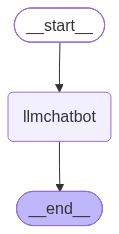

In [6]:
# Visualize the graph
from IPython.display import display,Image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed. Please ensure you have graphviz installed and configured correctly.")
    print(f"Error: {e}")

In [7]:
response = graph.invoke({"messages":["Hello, how are you?"]})
response["messages"]

[HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='66ecff5b-9fd0-40a2-ac56-79df1d50a0e6'),
 AIMessage(content="Hello! I'm just a language model, but I'm here and ready to help you. How can I assist you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 13, 'total_tokens': 37, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_8a456ba4f1', 'id': 'chatcmpl-EbRWVcC8Rb0RLznzID9nm1LbC9ykP', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15ed9-03ae-7728-b6cb-5554051e9651-0', tool_calls=[], invalid_tool_calls=[]

In [8]:
response = graph.invoke({"messages":["I Love you"]})
print(response["messages"])
print(response["messages"][-1].content)

[HumanMessage(content='I Love you', additional_kwargs={}, response_metadata={}, id='c247d36d-c4fb-4353-b811-d2638a4321af'), AIMessage(content="Aww, that's sweet! ❤️ I'm here for you—how can I help today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 10, 'total_tokens': 28, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_87b97c2d72', 'id': 'chatcmpl-EbRWWvT6PyZNtA8VLg5xHcbb11lNy', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15ed9-0736-757b-858c-2d753c63f0af-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_t

In [9]:
for event in graph.stream({"messages":["I Love you"]}):
    print(event)

{'llmchatbot': {'messages': [AIMessage(content="Aww, thank you! 😊 That’s so sweet of you to say. I'm here for you—how can I make your day better?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 29, 'prompt_tokens': 10, 'total_tokens': 39, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_87b97c2d72', 'id': 'chatcmpl-EbRWXTjATy6uO3g1Q8AnVAnZLoXzK', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15ed9-0cc8-7073-9a01-a031d6926112-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 29, 'total_tokens': 39, 'input_token_details': {'a

In [10]:
for event in graph.stream({"messages":["I Love you"]}):
    for value in event.values():
        print(value["messages"][-1].content )

Aww, thank you! 😊 I'm here for you whenever you need me. How can I help you today?


### Chatbot with Tool


In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model
from langchain_tavily import TavilySearch

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

tool = TavilySearch(max_results=3, search_type="web", search_mode="realtime")
tool.invoke("What is langgraph?")


{'query': 'What is langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how

In [6]:
# Custom Function

def multiply(a: int, b: int) -> int:
    """ Multiplies two integers and returns the result. """
    return a * b

tools = [tool, multiply]

from langchain.chat_models import init_chat_model
model = init_chat_model("openai:gpt-4.1")
llm = model

llm_with_tool= llm.bind_tools(tools)

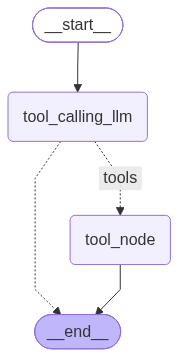

In [7]:
# Stategraph with tools
from langgraph.graph import StateGraph,  START, END
from langgraph.graph.message import add_messages # Reducer  - to add messages to the graph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# LLM Node
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

# Graph
builder = StateGraph(State)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tool_node", ToolNode(tools))

# Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition,{"tools":"tool_node","__end__":END})
# if the Latest message is a tool call, tool_condition will return True and the graph will go to the tool_node
# If the latest message is not a tool call, the tool_condition will return False and the graph will go to END
builder.add_edge("tool_node", END)

# Compile the graph
graph = builder.compile()

# Visualize the graph
from IPython.display import display,Image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed. Please ensure you have graphviz installed and configured correctly.")
    print(f"Error: {e}")

In [8]:
response = graph.invoke({"messages":["What is recent ai news? "]})
print(response["messages"][-1].content)

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://martech.org/the-latest-ai-powered-martech-news-and-releases", "title": "The latest AI-powered martech news and releases", "content": "## October 8, 2026\n\nAiseogic launched a free AI SEO audit platform for Google and AI search tools. It evaluates website content structure, measures brand visibility across AI answer engines, flags technical crawl barriers, and recommends optimizations for generative search platforms.\n\nAntavo brought loyalty program management capabilities into LLMs by launching a dedicated MCP server. It allows loyalty managers to configure reward structures, analyze program data, and execute operational adjustments inside conversational AI tools. [...] MediaRadar launched Insights Studio, an intelligence platform designed for ad sales teams and AI agents. It tracks multichannel advertising spend, evaluates competitor media strategies, and generates rev

In [9]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is recent ai news? 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_1lJZSia0zmdXast6RbYNNWHt)
 Call ID: call_1lJZSia0zmdXast6RbYNNWHt
  Args:
    query: recent AI news
    search_depth: advanced
    topic: news
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://martech.org/the-latest-ai-powered-martech-news-and-releases", "title": "The latest AI-powered martech news and releases", "content": "## October 8, 2026\n\nAiseogic launched a free AI SEO audit platform for Google and AI search tools. It evaluates website content structure, measures brand visibility across AI answer engines, flags technical crawl barriers, and recommends optimizations for gene

In [10]:
response = graph.invoke({"messages":["Multiply 5 and 2"]})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Multiply 5 and 2
================================== Ai Message ==================================
Tool Calls:
  multiply (call_PgBHhkabF7jgHPLdJctlxMYw)
 Call ID: call_PgBHhkabF7jgHPLdJctlxMYw
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [11]:
response = graph.invoke({"messages":[" 5 multiply by 2 and then Multiply  by 10?"]})
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model

================================ Human Message =================================

 5 multiply by 2 and then Multiply  by 10?
================================== Ai Message ==================================
Tool Calls:
  multiply (call_Xw3GMoIXg5Ax0Ba10J3YYnro)
 Call ID: call_Xw3GMoIXg5Ax0Ba10J3YYnro
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [12]:
# React Agent - Communication with tools and LLM -  Neeed to ?
response = graph.invoke({"messages":[" Give me recent ai news and then5 multiply by 10 "]})
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model

================================ Human Message =================================

 Give me recent ai news and then5 multiply by 10 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_13Q3KJ23x4Er2ruF12cobOqC)
 Call ID: call_13Q3KJ23x4Er2ruF12cobOqC
  Args:
    query: recent AI news
    search_depth: advanced
    topic: news
    time_range: week
  multiply (call_GveGNaxnI9XYZii8v0t21rdg)
 Call ID: call_GveGNaxnI9XYZii8v0t21rdg
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://martech.org/the-latest-ai-powered-martech-news-and-releases", "title": "The latest AI-powered martech news and releases", "content": "## October 8, 2026\n\nAiseogic launched a free AI SEO audit platform for Google and AI search tools. It evaluates website conte

### ReAct Agent Architecture

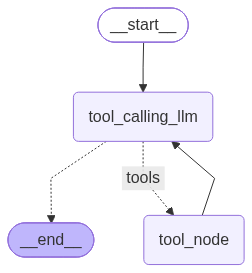

In [14]:
# Stategraph with tools
from langgraph.graph import StateGraph,  START, END
from langgraph.graph.message import add_messages # Reducer  - to add messages to the graph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# LLM Node
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

# Graph
builder = StateGraph(State)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tool_node", ToolNode(tools))

# Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition,{"tools":"tool_node","__end__":END})
# if the Latest message is a tool call, tool_condition will return True and the graph will go to the tool_node
# If the latest message is not a tool call, the tool_condition will return False and the graph will go to END
builder.add_edge("tool_node", "tool_calling_llm") # Loop back to the LLM node after the tool node

# Compile the graph
graph = builder.compile()

# Visualize the graph
from IPython.display import display,Image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed. Please ensure you have graphviz installed and configured correctly.")
    print(f"Error: {e}")

In [15]:
# React Agent - Communication with tools and LLM -  Neeed to ?
response = graph.invoke({"messages":[" Give me recent ai news and then5 multiply by 10 "]})
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model

================================ Human Message =================================

 Give me recent ai news and then5 multiply by 10 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_vp6YnFd4A4xH7y0EIhAOd1si)
 Call ID: call_vp6YnFd4A4xH7y0EIhAOd1si
  Args:
    query: recent AI news
    search_depth: advanced
    topic: news
  multiply (call_GQKHoHo1wb6301zKjrhWS7Az)
 Call ID: call_GQKHoHo1wb6301zKjrhWS7Az
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://fortune.com/2026/10/21/powerful-new-ai-models-are-powering-a-growing-wave-of-cyber-attacks-experts-say", "title": "Powerful new AI models are behind a wave of recent cyber attacks, experts say | Fortune", "content": "# 3\n\nUnitedHealthcare and Humana are ending Medicare Advantage 

### Adding Memory in Agentic Graph

Solves the Problem of Persistent Checkpointing - It does not remember my name

In [16]:

response = graph.invoke({"messages":[" Hello My Name Is Rakshith"]})
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model

================================ Human Message =================================

 Hello My Name Is Rakshith
================================== Ai Message ==================================

Hello Rakshith! How can I help you today?


In [17]:
# React Agent - Communication with tools and LLM -  Neeed to ?
response = graph.invoke({"messages":[" What is my Name ? "]})
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model

================================ Human Message =================================

 What is my Name ? 
================================== Ai Message ==================================

You haven’t provided your name. Could you please tell me your name or let me know if you’d like me to guess or use a placeholder?


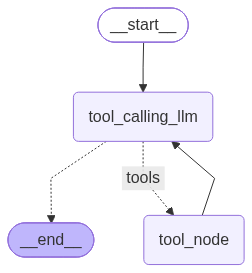

In [ ]:
# Stategraph with tools
from langgraph.graph import StateGraph,  START, END
from langgraph.graph.message import add_messages # Reducer  - to add messages to the graph
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

# LLM Node
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

# Graph
builder = StateGraph(State)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tool_node", ToolNode(tools))

# Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition,{"tools":"tool_node","__end__":END})
# if the Latest message is a tool call, tool_condition will return True and the graph will go to the tool_node
# If the latest message is not a tool call, the tool_condition will return False and the graph will go to END
builder.add_edge("tool_node", "tool_calling_llm") # Loop back to the LLM node after the tool node

# Compile the graph
graph = builder.compile(checkpointer=MemorySaver())

# Visualize the graph
from IPython.display import display,Image
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed. Please ensure you have graphviz installed and configured correctly.")
    print(f"Error: {e}")

In [25]:
config = {"configurable": {"thread_id": "thread_3"}}

response = graph.invoke({"messages":[" Hello My Name Is Rakshith"]}, config=config)
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model


================================ Human Message =================================

 Hello My Name Is Rakshith
================================== Ai Message ==================================

Hello Rakshith! How can I help you today?


In [ ]:

# The State stores all the messages in the thread. So, when we ask "What is my name?", 
# the model can refer to the previous message and answer correctly.
response = graph.invoke({"messages":[" What is my Name ? "]},config=config)
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model

================================ Human Message =================================

 Hello My Name Is Rakshith
================================== Ai Message ==================================

Hello Rakshith! How can I help you today?
================================ Human Message =================================

 What is my Name ? 
================================== Ai Message ==================================

Your name is Rakshith. How can I assist you further?


In [27]:

# The State stores all the messages in the thread. So, when we ask "What is my name?", 
# the model can refer to the previous message and answer correctly.
response = graph.invoke({"messages":[" Do you remember my name ? How can you remember it all my conversation ? "]},config=config)
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model

================================ Human Message =================================

 Hello My Name Is Rakshith
================================== Ai Message ==================================

Hello Rakshith! How can I help you today?
================================ Human Message =================================

 What is my Name ? 
================================== Ai Message ==================================

Your name is Rakshith. How can I assist you further?
================================ Human Message =================================

 Do you remember my name ? How can you remember it all my conversation ? 
================================== Ai Message ==================================

Yes, I remember your name is Rakshith because you told me earlier in this conversation. During our ongoing chat, I keep track of information you share (like your name) so I can make our conversation more natural and helpful.

However, I don’t have memory between conversations for privacy rea

### Streaming


In [29]:
from langgraph.checkpoint.memory import MemorySaver
memory_saver = MemorySaver()

In [30]:
def superbot(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

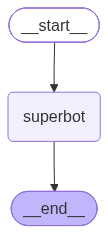

In [33]:
graph = StateGraph(State)

# Node
graph.add_node("superbot", superbot)
graph.add_edge(START, "superbot")
graph.add_edge("superbot", END)

graph_builder = graph.compile(checkpointer=MemorySaver())

# Visualize the graph
from IPython.display import display,Image
try:
    display(Image(graph_builder.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed. Please ensure you have graphviz installed and configured correctly.")
    print(f"Error: {e}")


In [35]:
config = {"configurable": {"thread_id": "thread_1"}}

response = graph_builder.invoke({"messages":[" Hello My Name Is Rakshith and I like Basketball"]}, config=config)
for m in response["messages"]:
    m.pretty_print() # Haven't seen the output with gpt model


================================ Human Message =================================

 Hello My Name Is Rakshith and I like Basketball
================================== Ai Message ==================================

Hi Rakshith! It’s great to meet you. That’s awesome that you like basketball! Do you play on a team, follow the NBA, or just enjoy shooting hoops for fun? Let me know what you’re most interested in—I’d love to chat more about basketball or anything else you like!



Methods: .stream() and astream()
- These methods are sync and async methods for streaming back results

Additional parameters in streaming modes for graph state
- values : This streams the full state of the graph after each node is called
- updates : This steams updates to the state of the graph after each node is called

In [38]:
config = {"configurable": {"thread_id": "thread_4"}}
for chunk in graph_builder.stream({"messages":[" Hello My Name Is Rakshith and I like Basketball"]}, config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content=' Hello My Name Is Rakshith and I like Basketball', additional_kwargs={}, response_metadata={}, id='3eff0c87-36c1-44f8-be43-afe7f57c8617')]}
{'messages': [HumanMessage(content=' Hello My Name Is Rakshith and I like Basketball', additional_kwargs={}, response_metadata={}, id='3eff0c87-36c1-44f8-be43-afe7f57c8617'), AIMessage(content="Hello Rakshith! It's great to meet you. Basketball is an awesome sport—do you have a favorite team or player? Or do you enjoy playing the game yourself? Let me know how you'd like to talk more about basketball!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 48, 'prompt_tokens': 1225, 'total_tokens': 1273, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': Non

In [36]:
config = {"configurable": {"thread_id": "thread_3"}}
for chunk in graph_builder.stream({"messages":[" Hello My Name Is Rakshith and I like Basketball"]}, config=config,stream_mode="updates"):
    print(chunk)

{'superbot': {'messages': [AIMessage(content='Hello Rakshith! It’s great to meet you. That’s awesome that you like basketball! Who’s your favorite basketball team or player? Do you play for fun or follow the professional leagues?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 1225, 'total_tokens': 1266, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_98b0337892', 'id': 'chatcmpl-Ebf7OaAnEx1rn2yypdg7CWAQz5rae', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a161f6-6a7f-746c-a0b8-f22674ef25bb-0', tool_calls=[], invalid_tool_calls=[], usage_metada

In [44]:
config = {"configurable": {"thread_id": "thread_6"}}
for chunk in graph_builder.stream({"messages":[" Hello My Name Is Rakshith and I like Cricket"]}, config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content=' I also like Football', additional_kwargs={}, response_metadata={}, id='40c98006-f6f8-4028-9ca5-c91d8f886e57'), AIMessage(content="That's great to hear! Football (soccer or American football, depending on where you're from) is one of the most popular sports worldwide. Do you have a favorite team or player? Are you interested in a specific league or tournament, or do you like playing the sport yourself? Let me know how you're interested in football, and I can share news, stats, history, or even tips to improve your own game!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 85, 'prompt_tokens': 1218, 'total_tokens': 1303, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': None, 'text_tokens

In [43]:
config = {"configurable": {"thread_id": "thread_6"}}
for chunk in graph_builder.stream({"messages":[" I also like Football"]}, config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content=' I also like Football', additional_kwargs={}, response_metadata={}, id='40c98006-f6f8-4028-9ca5-c91d8f886e57'), AIMessage(content="That's great to hear! Football (soccer or American football, depending on where you're from) is one of the most popular sports worldwide. Do you have a favorite team or player? Are you interested in a specific league or tournament, or do you like playing the sport yourself? Let me know how you're interested in football, and I can share news, stats, history, or even tips to improve your own game!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 85, 'prompt_tokens': 1218, 'total_tokens': 1303, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': None, 'text_tokens

In [46]:
config = {"configurable": {"thread_id": "thread_7"}}
async for event in graph_builder.astream_events({"messages":[" Hello My Name Is Rakshith and I like Cricket"]}, config=config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': [' Hello My Name Is Rakshith and I like Cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a161fc-8b67-714f-bfe2-0d62e986d466', 'metadata': {'thread_id': 'thread_7', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content=' Hello My Name Is Rakshith and I like Cricket', additional_kwargs={}, response_metadata={}, id='03535a3b-c8f1-4b4c-9e23-be8e8247205c'), AIMessage(content="Hello Rakshith! It's great to meet you. Cricket is an amazing sport—are you a fan of any particular team or player? Do you play cricket yourself, or mostly enjoy watching it? Let me know if you’d like to chat about cricket, need stats, news, or anything else!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 62, 'prompt_tokens': 1225, 'total_tokens': 1287, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens